# 미국 TSA 보안검색 통과자 수 분석 (2019~2026)

데이터: `collect_data.py`로 tsa.gov에서 수집한 일별 통과자 수

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'AppleGothic'  # 한글 깨짐 방지 (mac)
plt.rcParams['axes.unicode_minus'] = False

# 설정
DATA_PATH = 'data/tsa_daily.csv'
DATE_COL = 'date'
VALUE_COL = 'passengers'

## 1. 데이터 불러오기 · 기본 정보

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=[DATE_COL])
df = df.sort_values(DATE_COL).set_index(DATE_COL)
print(df.shape)
print(df.index.min(), '~', df.index.max())
df.info()
df.head()

(2835, 1)
2019-01-01 00:00:00 ~ 2026-10-05 00:00:00
<class 'pandas.DataFrame'>
DatetimeIndex: 2835 entries, 2019-01-01 to 2026-10-05
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   passengers  2835 non-null   int64
dtypes: int64(1)
memory usage: 44.3 KB


,passengers
date,
2019-01-01,2201765
2019-01-02,2424225
2019-01-03,2279384
2019-01-04,2230078
2019-01-05,2049460


## 2. 정제: 결측치 · 중복 · 이상치

In [3]:
print('결측치:\n', df.isna().sum())
print('중복 날짜:', df.index.duplicated().sum())
df[VALUE_COL].describe()

결측치:
 passengers    0
dtype: int64
중복 날짜: 0


count    2.835000e+03
mean     2.077104e+06
std      6.506654e+05
min      1.131470e+05
25%      1.879716e+06
50%      2.224826e+06
75%      2.541850e+06
max      3.134613e+06
Name: passengers, dtype: float64

In [4]:
df['ma_7'] = df[VALUE_COL].rolling(7).mean()
df['ma_30'] = df[VALUE_COL].rolling(30).mean()
df['pct_change'] = df[VALUE_COL].pct_change() * 100
# 전년 같은 요일 대비 변화율 (364일 = 52주 전)
df['yoy_pct'] = (df[VALUE_COL] / df[VALUE_COL].shift(364) - 1) * 100
df['weekday'] = df.index.day_name()
monthly = df[VALUE_COL].resample('MS').mean()
monthly.tail()

date
2026-06-01    2.691045e+06
2026-07-01    2.688392e+06
2026-08-01    2.477173e+06
2026-09-01    2.353904e+06
2026-10-01    2.572682e+06
Freq: MS, Name: passengers, dtype: float64

## 3. 시계열 분석 기법 (최소 2가지)

In [5]:
df['ma_7'] = df[VALUE_COL].rolling(7).mean()
df['ma_30'] = df[VALUE_COL].rolling(30).mean()
df['pct_change'] = df[VALUE_COL].pct_change() * 100
monthly = df[VALUE_COL].resample('MS').mean()
monthly.tail()

date
2026-06-01    2.691045e+06
2026-07-01    2.688392e+06
2026-08-01    2.477173e+06
2026-09-01    2.353904e+06
2026-10-01    2.572682e+06
Freq: MS, Name: passengers, dtype: float64

## 4. 시각화

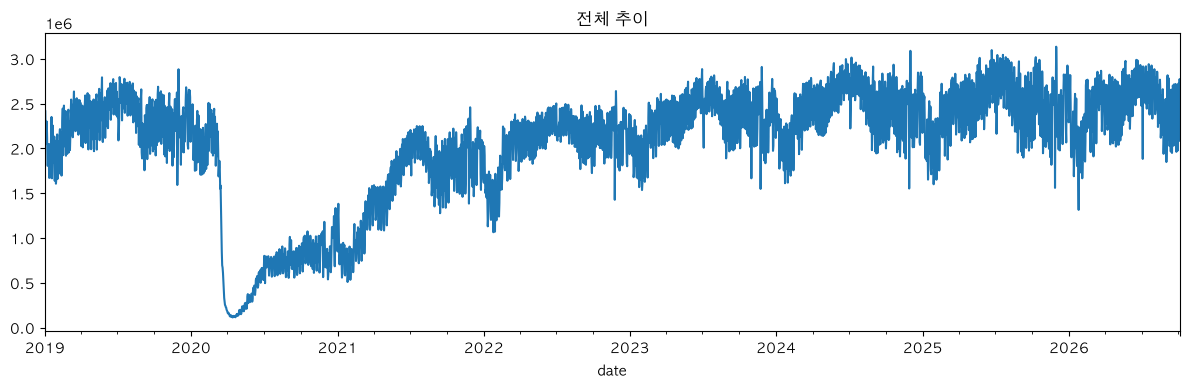

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
df[VALUE_COL].plot(ax=ax)
ax.set_title('전체 추이')
plt.tight_layout(); plt.savefig('images/01_trend.png', dpi=150); plt.show()

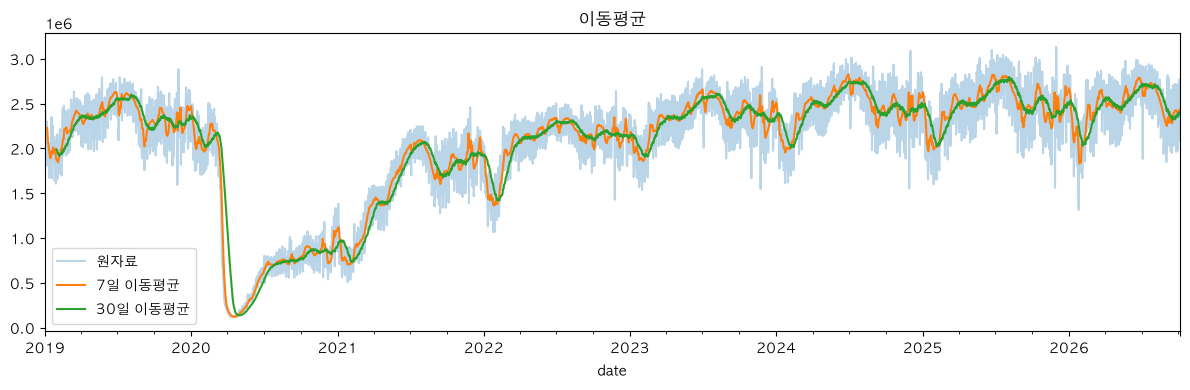

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
df[VALUE_COL].plot(ax=ax, alpha=0.3, label='원자료')
df['ma_7'].plot(ax=ax, label='7일 이동평균')
df['ma_30'].plot(ax=ax, label='30일 이동평균')
ax.set_title('이동평균'); ax.legend()
plt.tight_layout(); plt.savefig('images/02_moving_average.png', dpi=150); plt.show()

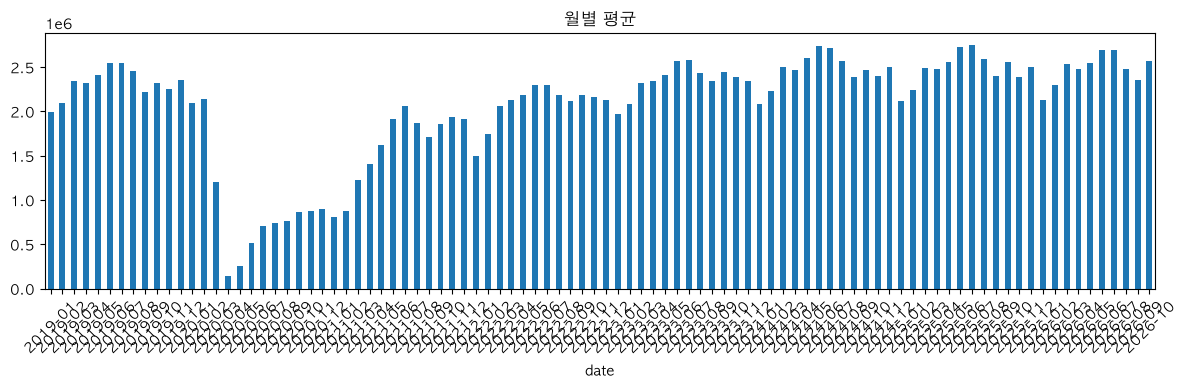

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(kind='bar', ax=ax)
ax.set_title('월별 평균')
ax.set_xticklabels([d.strftime('%Y-%m') for d in monthly.index], rotation=45)
plt.tight_layout(); plt.savefig('images/03_monthly.png', dpi=150); plt.show()

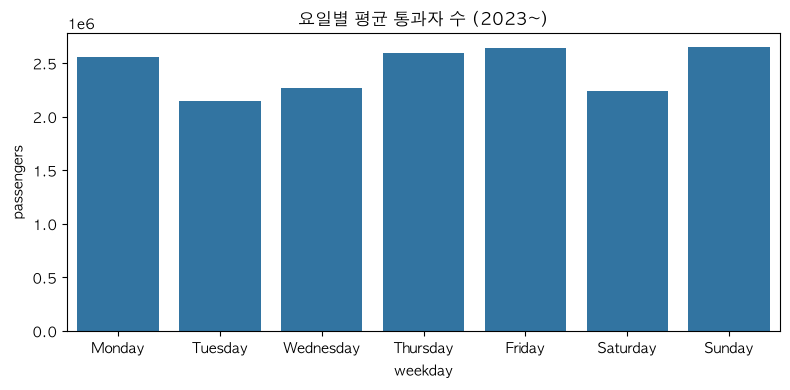

In [9]:
# 요일별 평균 (2023년 이후, 코로나 영향 제외)
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
recent = df[df.index >= '2023-01-01']
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x='weekday', y=VALUE_COL, data=recent, order=order, ax=ax, errorbar=None)
ax.set_title('요일별 평균 통과자 수 (2023~)')
plt.tight_layout(); plt.savefig('images/04_weekday.png', dpi=150); plt.show()

In [10]:
# 가장 붐빈 날 / 가장 한산한 날 Top 5
print(df[VALUE_COL].nlargest(5))
print(df[df.index >= '2021-01-01'][VALUE_COL].nsmallest(5))

date
2025-11-30    3134613
2025-06-22    3096797
2024-12-01    3088836
2025-07-20    3043973
2025-07-06    3041954
Name: passengers, dtype: int64
date
2021-01-26    508467
2021-02-02    532690
2021-01-12    557517
2021-01-27    574099
2021-01-20    581771
Name: passengers, dtype: int64


## 5. 메모 (관찰 / 해석)

- 관찰:
- 해석: